# Где и на каком этапе меняется выборка

## Продолжение эксперимента A

Первый ноутбук проверяет входы и рассчитывает все группы. Здесь разбираем его
агрегаты: какие этапы меняют покрытие и где сосредоточены потери GoA.
Расчеты не требуют повторного чтения миллионов записей.

**Важно:** максимальная абсолютная потеря часто относится к большой группе;
ее нужно отличать от низкой доли сохранения. Причины этапов описывают правила,
а не доказанный механизм потери наблюдений.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd().resolve()
while not (ROOT/'reports/selection_summary.csv').exists():
    if ROOT == ROOT.parent: raise FileNotFoundError('Сначала выполните 01_selection_effects.ipynb')
    ROOT = ROOT.parent
R = ROOT/'reports'; F = ROOT/'figures'
verification = json.loads((R/'verification.json').read_text(encoding='utf-8'))
assert all(c['passed'] for c in verification['ordered_checks'])
stages = ['source','pairs','complete','temporal','final']
names = ['Неоднозначные пары','Неполный / неконечный C40','Временное условие','Согласованные случаи']
summary=pd.read_csv(R/'selection_summary.csv').set_index('stage')
registry=pd.read_csv(R/'stage_registry.csv')
prior_rows=int(summary.loc['source','rows']); prior_goa=int(summary.loc['source','goa'])
prior_output=None
for i,row in registry.iterrows():
    if prior_output is not None:
        assert row['input'].replace(chr(92),'/') == prior_output.replace(chr(92),'/')
    if pd.notna(row.rows_before): assert int(row.rows_before)==prior_rows
    registry.loc[i,'rows_before']=prior_rows
    registry.loc[i,'goa_before']=prior_goa
    if pd.isna(row.goa_after):
        assert int(row.rows_after)==prior_rows
        registry.loc[i,'goa_after']=prior_goa
    prior_rows=int(row.rows_after); prior_goa=int(registry.loc[i,'goa_after'])
    prior_output=row['output']
registry['changes_population']=registry.rows_before.ne(registry.rows_after)
registry.to_csv(R/'stage_registry_completed.csv',index=False)
display(registry[['journal','rows_before','rows_after','goa_before','goa_after','changes_population']])
plt.rcParams.update({'figure.dpi':120,'font.size':11,'axes.spines.top':False,
 'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18})
def save(name):
    plt.tight_layout()
    for ext in ['png','svg']: plt.savefig(F/f'{name}.{ext}',bbox_inches='tight')
    plt.show()


,journal,rows_before,rows_after,goa_before,goa_after,changes_population
0,europe/reports/preparation/01_empty_strings_no...,7984254.0,7984254,26253.0,26253.0,False
1,europe/reports/preparation/04_aircraft_referen...,7984254.0,7984254,26253.0,26253.0,False
2,europe/reports/preparation/07_c40_flags_applie...,7984254.0,7984254,26253.0,26253.0,False
3,europe/reports/analytical_sample/04_08_pairs_e...,7984254.0,7983960,26253.0,26250.0,True
4,europe/reports/analytical_sample/04_10_c40_app...,7983960.0,6331494,26250.0,18358.0,True
5,europe/reports/aircraft_types/05_03_restoratio...,6331494.0,6331494,18358.0,18358.0,False
6,europe/reports/aircraft_types/05_04_applied.json,6331494.0,6331494,18358.0,18358.0,False
7,europe/reports/aircraft_types/05_05_applied.json,6331494.0,6331494,18358.0,18358.0,False
8,europe/reports/attempts/LSGG/06_02_exclusion_a...,6331494.0,6331493,18358.0,18357.0,True
9,europe/reports/attempts/06_04_cfl12_exclusion_...,6331493.0,6331492,18357.0,18356.0,True


## 1. Потери на переходах для каждой группы

Для этапа k потери равны N(k−1) − N(k). Каждая запись входит в первый
непройденный переход. Результаты вложенных этапов не суммируются повторно.
Переход полноты объединяет пропуски и неконечные числа; точные отдельные причины
сохраняются в первом ноутбуке.

In [2]:
losses = {}; distribution = []
for group in ['airport','year','month','typecode','market_segment']:
    a = pd.read_csv(R/f'by_{group}_all_stages.csv',dtype={group:str})
    n = a.pivot(index=group,columns='stage',values='rows').reindex(columns=stages).fillna(0)
    g = a.pivot(index=group,columns='stage',values='goa').reindex(columns=stages).fillna(0)
    assert (n.diff(axis=1).iloc[:,1:]<=0).all().all()
    assert (g.diff(axis=1).iloc[:,1:]<=0).all().all()
    pieces=[]
    for i in range(1,len(stages)):
        q=pd.DataFrame({'rows_removed':n.iloc[:,i-1]-n.iloc[:,i],
                        'goa_removed':g.iloc[:,i-1]-g.iloc[:,i]})
        q['step']=names[i-1]
        q['retained_step_pct']=100*n.iloc[:,i]/n.iloc[:,i-1].replace(0,np.nan)
        q['positive_retained_step_pct']=100*g.iloc[:,i]/g.iloc[:,i-1].replace(0,np.nan)
        pieces.append(q.reset_index())
    loss=pd.concat(pieces,ignore_index=True)
    loss.to_csv(R/f'transition_losses_{group}.csv',index=False); losses[group]=loss
    shares=n.div(n.sum(axis=0),axis=1)
    # TV – половина суммы абсолютных изменений весов групп, диапазон 0–1.
    distribution.append({'group':group,'composition_total_variation':
                          .5*(shares.final-shares.source).abs().sum()})
display(pd.DataFrame(distribution))
pd.DataFrame(distribution).to_csv(R/'composition_distance.csv',index=False)
display(losses['year'].style.format(precision=3))


,group,composition_total_variation
0,airport,0.073891
1,year,0.034833
2,month,0.035112
3,typecode,0.134577
4,market_segment,0.081570


,year,rows_removed,goa_removed,step,retained_step_pct,positive_retained_step_pct
0,2019,294,3,Неоднозначные пары,99.988,99.959
1,2020,0,0,Неоднозначные пары,100.000,100.000
2,2021,0,0,Неоднозначные пары,100.000,100.000
3,2022,0,0,Неоднозначные пары,100.000,100.000
4,2023,0,0,Неоднозначные пары,100.000,100.000
5,2019,343794,1258,Неполный / неконечный C40,86.336,82.605
6,2020,185926,1251,Неполный / неконечный C40,83.243,69.525
7,2021,299058,1818,Неполный / неконечный C40,78.143,60.794
8,2022,577958,2450,Неполный / неконечный C40,73.704,67.185
9,2023,245646,1070,Неполный / неконечный C40,68.993,61.922


## 2. Потери положительных меток и их этапы

Берем 15 аэропортов с наибольшей суммарной потерей GoA. Полная таблица содержит
все аэропорты. Условия C40 могут быть связаны с особенностями покрытия источника
или события; причинная трактовка требует отдельной проверки.

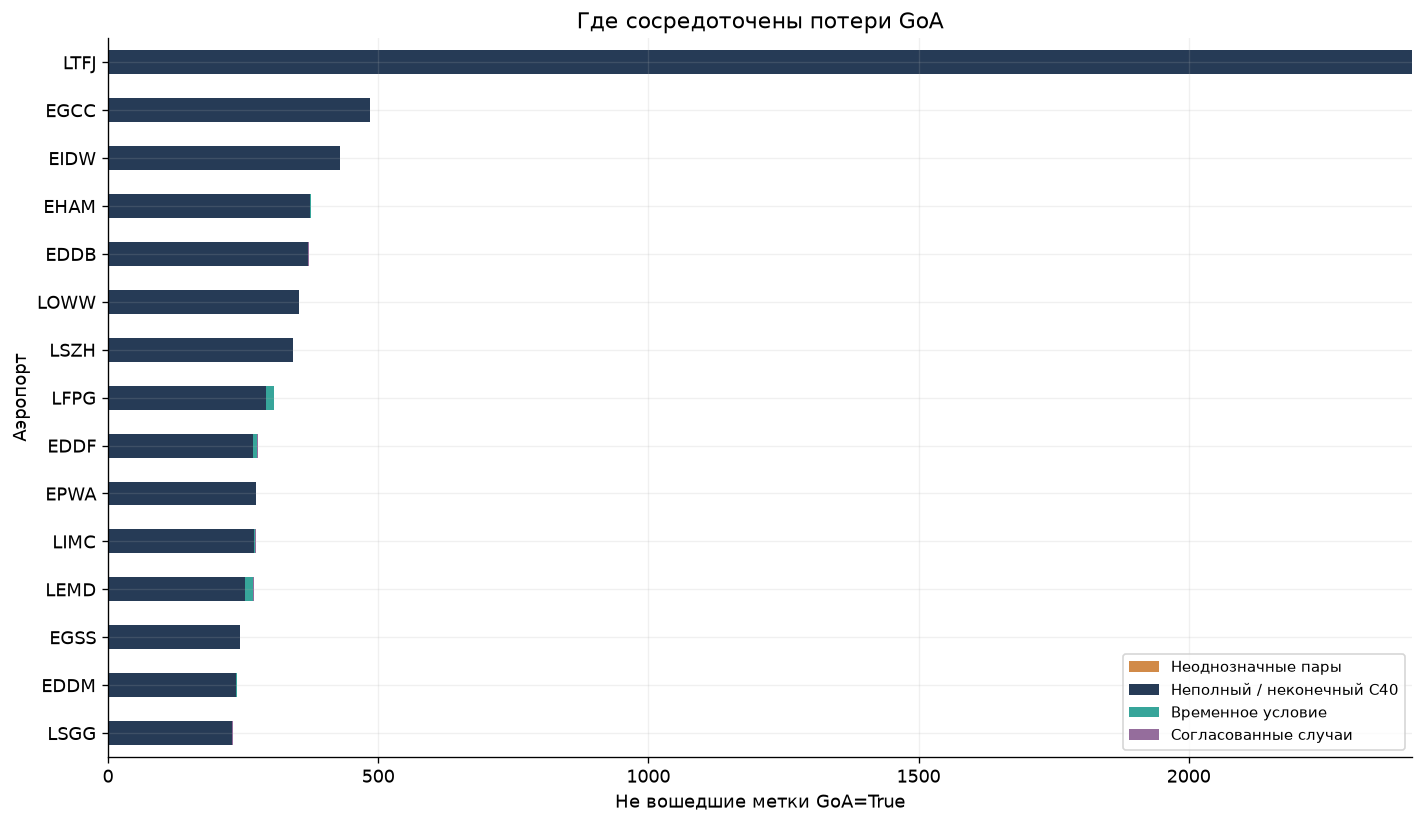

step,Неоднозначные пары,Неполный / неконечный C40,Временное условие,Согласованные случаи,total
airport,,,,,
LTFJ,0,2414,0,0,2414
EGCC,0,485,0,0,485
EIDW,0,430,0,0,430
EHAM,0,374,2,0,376
EDDB,0,370,1,1,372
LOWW,0,354,0,0,354
LSZH,0,342,0,0,342
LFPG,1,291,15,0,307
EDDF,1,268,6,2,277


,rows_source,goa_source,rows_outside,goa_outside,positive_retained_pct,negative_retained_pct,retention_gap_pp
airport,,,,,,,
LTFJ,387368,2414,387368.000,2414.000,0.000,0.000,0.000
EGCC,211299,791,123864.000,485.000,38.685,41.390,-2.705
EIDW,313008,1352,49129.000,430.000,68.195,84.374,-16.179
EHAM,639766,1414,78285.000,376.000,73.409,87.795,-14.387
EDDB,216588,799,68252.000,372.000,53.442,68.543,-15.102
LOWW,360091,1375,66513.000,354.000,74.255,81.557,-7.302
LSZH,372304,1486,55331.000,342.000,76.985,85.171,-8.186
LFPG,701670,2653,84108.000,307.000,88.428,88.012,0.417
EDDF,644881,2161,39921.000,277.000,87.182,93.832,-6.650


In [3]:
p=losses['airport'].pivot(index='airport',columns='step',values='goa_removed').reindex(columns=names)
top=p.sum(axis=1).nlargest(15).index
q=p.loc[top].iloc[::-1]
q.plot.barh(stacked=True,figsize=(12,7),color=['#d18a48','#263b56','#37a59a','#956d9c'])
plt.xlabel('Не вошедшие метки GoA=True'); plt.ylabel('Аэропорт')
plt.title('Где сосредоточены потери GoA'); plt.legend(loc='lower right',fontsize=9)
save('07_positive_losses_by_stage')
display(p.loc[top].assign(total=p.loc[top].sum(axis=1)).style.format(precision=0))
c=pd.read_csv(R/'comparison_airport.csv').set_index('airport')
c['retention_gap_pp']=c.positive_retained_pct-c.negative_retained_pct
display(c.loc[top,['rows_source','goa_source','rows_outside','goa_outside',
 'positive_retained_pct','negative_retained_pct','retention_gap_pp']].style.format(precision=3))


## 3. Покрытие по аэропортам и времени

Тепловая карта ниже построена из уже агрегированных разрезов года и аэропорта
раздельно: совместный разрез аэропорт × год не рассчитывался. Поэтому показываем
аэропорт × этап и отдельно год × этап, не восстанавливая отсутствующую таблицу.

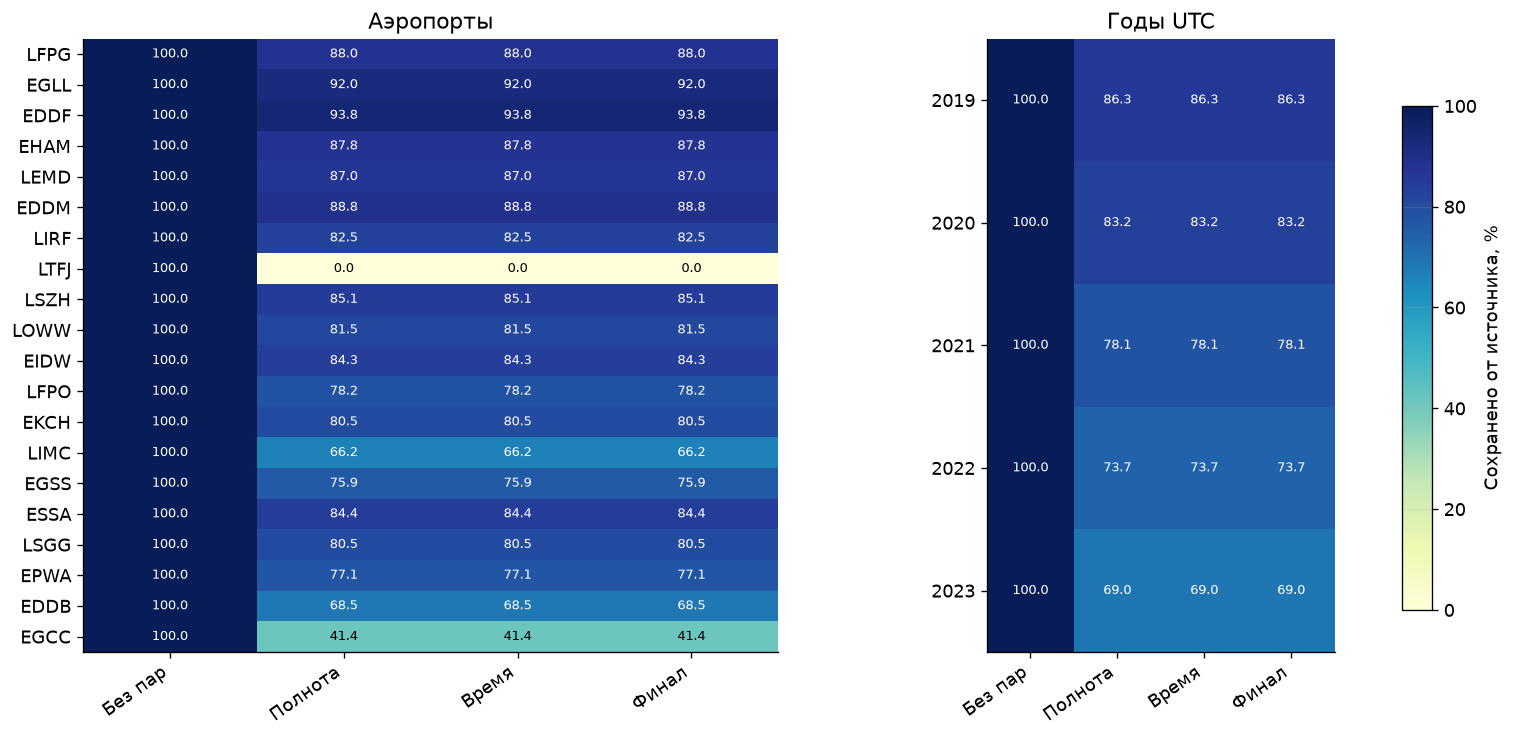

In [4]:
fig,axes=plt.subplots(1,2,figsize=(14,7),gridspec_kw={'width_ratios':[2,1]})
for ax,group,limit in [(axes[0],'airport',20),(axes[1],'year',10)]:
    a=pd.read_csv(R/f'by_{group}_all_stages.csv',dtype={group:str})
    p=a.pivot(index=group,columns='stage',values='rows').reindex(columns=stages).fillna(0)
    p=p.loc[p.source.nlargest(limit).index] if group=='airport' else p.sort_index()
    retention=100*p.iloc[:,1:].div(p.source,axis=0)
    im=ax.imshow(retention,aspect='auto',vmin=0,vmax=100,cmap='YlGnBu')
    ax.set_yticks(range(len(p)),p.index)
    ax.set_xticks(range(4),['Без пар','Полнота','Время','Финал'],rotation=35,ha='right')
    ax.set_title('Аэропорты' if group=='airport' else 'Годы UTC'); ax.grid(False)
    for i in range(len(p)):
        for j in range(4):
            val=retention.iloc[i,j]
            ax.text(j,i,f'{val:.1f}',ha='center',va='center',fontsize=8,
                    color='white' if val>65 else 'black')
fig.subplots_adjust(bottom=.15,right=.87,wspace=.4)
colorbar_axis=fig.add_axes([.91,.2,.018,.6])
fig.colorbar(im,cax=colorbar_axis,label='Сохранено от источника, %')
for ext in ['png','svg']: fig.savefig(F/f'08_retention_heatmap.{ext}',bbox_inches='tight')
plt.show()


## 4. Краткий предметный разбор

Текст формируется из результатов. Это описание измеренных эффектов, а не
автоматическое решение об исключениях. Современные справочники типов и
предикторы будущего события в этот эксперимент не добавлялись.

In [5]:
total=losses['airport'].groupby('step')[['rows_removed','goa_removed']].sum().reindex(names)
dominant=total.goa_removed.idxmax()
worst=c.loc[(c.rows_source>=1000)&(c.rows_final>=1000),'retention_gap_pp'].idxmin()
missing=pd.read_csv(R/'comparison_typecode.csv').set_index('typecode').loc['[пропуск]']
absent=c.loc[c.rows_final.eq(0),['rows_source','goa_source','retained_pct']].sort_values('rows_source',ascending=False)
display(absent.style.format(precision=2))
absent.to_csv(R/'airports_without_final_coverage.csv')
months=pd.read_csv(R/'comparison_month.csv')['month']
text=f"""### Измеренные различия

- Наибольшая абсолютная потеря положительных меток приходится на этап **{dominant}**:
  **{int(total.loc[dominant,'goa_removed']):,}** GoA, **{int(total.loc[dominant,'rows_removed']):,}** записей.
- Среди аэропортов с N источника и финала ≥ 1000 наибольший отрицательный разрыв
  сохранения меток у **{worst}**: GoA=True **{c.loc[worst,'positive_retained_pct']:.2f}%**,
  GoA=False **{c.loc[worst,'negative_retained_pct']:.2f}%**.
- Исходный typecode отсутствует у **{int(missing.rows_source):,}** записей;
  после отбора сохранено **{missing.retained_pct:.2f}%** этой группы.
- В LTFJ не сохранилось ни одной из **{int(c.loc['LTFJ','rows_source']):,}** записей
  с **{int(c.loc['LTFJ','goa_source']):,}** GoA. Это следствие условия полноты C40;
  самостоятельное аэропортовое исключение здесь не вводилось.
- Доступные месяцы: **{months.min()} – {months.max()}**. 2023 год неполный;
  годовые объемы не являются сравнением полных календарных лет.

Первый эффект говорит о масштабе условия C40, второй – о неоднородности покрытия
по меткам, третий – об отличии доступности справочных сведений. Возможные причины
этих различий пока не установлены. До моделирования нужно явно задать целевую
популяцию, а затем исследовать временную доступность признаков.
"""
display(Markdown(text))
(R/'group_findings.md').write_text(text,encoding='utf-8')


,rows_source,goa_source,retained_pct
airport,,,
LTFJ,387368,2414,0.00


### Измеренные различия

- Наибольшая абсолютная потеря положительных меток приходится на этап **Неполный / неконечный C40**:
  **7,847** GoA, **1,652,382** записей.
- Среди аэропортов с N источника и финала ≥ 1000 наибольший отрицательный разрыв
  сохранения меток у **EIDW**: GoA=True **68.20%**,
  GoA=False **84.37%**.
- Исходный typecode отсутствует у **1,334,092** записей;
  после отбора сохранено **16.62%** этой группы.
- В LTFJ не сохранилось ни одной из **387,368** записей
  с **2,414** GoA. Это следствие условия полноты C40;
  самостоятельное аэропортовое исключение здесь не вводилось.
- Доступные месяцы: **2019-01 – 2023-05**. 2023 год неполный;
  годовые объемы не являются сравнением полных календарных лет.

Первый эффект говорит о масштабе условия C40, второй – о неоднородности покрытия
по меткам, третий – об отличии доступности справочных сведений. Возможные причины
этих различий пока не установлены. До моделирования нужно явно задать целевую
популяцию, а затем исследовать временную доступность признаков.


1033